# 17 — G01 : contrôler, réparer et comparer les géométries

**Projet autonome · 35 minutes · Cartomize 1.8.0 · données entièrement simulées**

Trois parcelles ont des situations différentes : un contour se croise, un carré est valide et une parcelle étroite risque de disparaître si la grille choisie est trop grossière. Deux autres enregistrements ont une géométrie vide ou manquante. Nous allons conserver leurs identifiants, choisir les règles, puis rouvrir les résultats avec la source complète.

**À la fin du cours :** sélectionner une couche ; lire le diagnostic ; distinguer réparation et réduction de précision ; traiter les exclusions ; vérifier les correspondances après export. Les surfaces attendues sont connues par construction, indépendamment de Cartomize.

Aucun téléchargement ni donnée privée n'est nécessaire. Le [guide G01](../../docs/G01_GEOMETRY_QUALITY.md) détaille les unités, les limites Z/M et la validation sur les données réelles épinglées.

In [1]:
from pathlib import Path
import json
import sqlite3
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from shapely.geometry import Point, Polygon
from IPython.display import display
%matplotlib inline

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from course import run_directory
import cartomize as cm

out = run_directory("17_g01_controle_reparation_geometries")
print("Cartomize", cm.__version__, "— dossier pédagogique :", out.name)

Cartomize 1.8.0 — dossier pédagogique : 17_g01_controle_reparation_geometries__ryzywyz


## 1. Cinq enregistrements, cinq identifiants

Les codes `001` à `005` sont des attributs métier textuels. Les positions `source_row` du rapport seront différentes de ces codes et commenceront à zéro. Les coordonnées sont inventées dans un SCR projeté en mètres ; elles ne décrivent aucune parcelle réelle.

Le carré `002` mesure 0,8 m de côté, donc **0,64 m²**. La parcelle `003` mesure 0,3 m × 2 m, donc **0,6 m²**. Le contour croisé `001` contient deux triangles de 1 m² lorsque la règle *linework* le reconstruit.

In [2]:
croisee = Polygon([(0, 0), (2, 2), (0, 2), (2, 0), (0, 0)])
carree = Polygon([(3.1, .1), (3.9, .1), (3.9, .9), (3.1, .9), (3.1, .1)])
etroite = Polygon([(5.1, .1), (5.4, .1), (5.4, 2.1), (5.1, 2.1), (5.1, .1)])
source = gpd.GeoDataFrame({
    "parcelle_id": ["001", "002", "003", "004", "005"],
    "nom": ["Contour croisé", "Carré valide", "Parcelle étroite", "Géométrie vide", "Géométrie manquante"],
}, geometry=[croisee, carree, etroite, Polygon(), None], crs="EPSG:32733")
source.index = [7, 7, 8, 8, 9]  # L'index pandas ne sert pas d'identifiant métier.
source_wkb = source.geometry.to_wkb().tolist()
display(source.drop(columns="geometry"))
assert source.parcelle_id.is_unique

,parcelle_id,nom
7,001,Contour croisé
7,002,Carré valide
8,003,Parcelle étroite
8,004,Géométrie vide
9,005,Géométrie manquante


## 2. Diagnostiquer la source sans la modifier

La validité GEOS est planaire : elle décrit XY. Le rapport distingue les vides, les absences et les géométries invalides. Les coordonnées, les parties, la présence de Z/M et l'empreinte WKB complètent le diagnostic. Une empreinte identique signifie que la représentation WKB est inchangée ; elle ne certifie pas la qualité métier.

`audit.before` et `audit.data` conservent ici la source complète. `audit.issues` rassemble les enregistrements signalés.

In [3]:
audit = cm.audit_geometries(source, id_field="parcelle_id")
display(audit.report[["source_row", "feature_id", "status", "reason",
                      "geometry_type", "coordinate_count", "part_count", "has_z", "has_m"]])
assert audit.report.status.tolist() == ["invalid", "valid", "valid", "empty", "missing"]
assert audit.report.output_row.tolist() == list(range(5))
assert audit.report.feature_id.tolist() == source.parcelle_id.tolist()
assert audit.before.geometry.to_wkb().tolist() == source_wkb
assert source.geometry.to_wkb().tolist() == source_wkb
print("Anomalies signalées :", len(audit.issues))

,source_row,feature_id,status,reason,geometry_type,coordinate_count,part_count,has_z,has_m
0,0,001,invalid,Self-intersection[1 1],Polygon,5,1,False,False
1,1,002,valid,Valid Geometry,Polygon,5,1,False,False
2,2,003,valid,Valid Geometry,Polygon,5,1,False,False
3,3,004,empty,Empty geometry,Polygon,0,0,False,False
4,4,005,missing,Missing geometry,NaN,0,0,False,False


Anomalies signalées : 3


## 3. Réparer à précision originale

Nous choisissons `linework`, une grille désactivée (`tolerance=0`) et l'exclusion explicite des géométries vides ou manquantes. Les géométries déjà valides restent inchangées. Le contour croisé devient un MultiPolygon : ce changement est autorisé et enregistré.

L'aire du contour invalide avant réparation n'est pas une surface territoriale validée. Le résultat attendu de 2 m² vient des deux triangles de la construction.

In [4]:
repare = cm.repair_geometries(source, id_field="parcelle_id", method="linework",
                               tolerance=0, empty="drop", missing="drop", type_changes="allow")
colonnes = ["feature_id", "decision", "output_row", "rejected_row",
            "before_geometry_type", "after_geometry_type", "after_area_m2"]
display(repare.report[colonnes])
assert repare.data.parcelle_id.tolist() == ["001", "002", "003"]
assert repare.rejected.parcelle_id.tolist() == ["004", "005"]
np.testing.assert_allclose(repare.report.after_area_m2.iloc[:3], [2, .64, .6], atol=1e-12)
assert repare.data.geometry.iloc[1].wkb == carree.wkb
assert repare.data.geometry.iloc[2].wkb == etroite.wkb
assert not repare.report.precision_changed.any()

,feature_id,decision,output_row,rejected_row,before_geometry_type,after_geometry_type,after_area_m2
0,001,repaired,0,<NA>,Polygon,MultiPolygon,2.00
1,002,unchanged,1,<NA>,Polygon,Polygon,0.64
2,003,unchanged,2,<NA>,Polygon,Polygon,0.60
3,004,dropped_empty,<NA>,0,Polygon,Polygon,0.00
4,005,dropped_missing,<NA>,1,NaN,NaN,NaN


## 4. Une grille demandée peut changer une géométrie valide

Le paramètre `tolerance` représente un **pas de grille XY en unités du SCR source projeté**. Ici, 1 signifie un mètre. Le traitement diagnostique la source, répare les invalides, applique la grille `valid_output`, puis contrôle le résultat.

Ce pas est volontairement grossier pour rendre l'effet visible. Il n'est pas une recommandation de précision. Le carré devient un carré de 1 m² ; la parcelle étroite s'effondre et suit notre politique `empty="drop"`. La grille ne fusionne pas les enregistrements entre eux.

`keep_collapsed` concerne la réparation GEOS, pas les parties qu'une grille supprime.

In [5]:
grille = cm.repair_geometries(source, id_field="parcelle_id", method="linework",
                              tolerance=1, empty="drop", missing="drop", type_changes="allow")
display(grille.report[["feature_id", "decision", "repair_changed", "precision_changed",
                       "before_coordinate_count", "after_coordinate_count",
                       "before_area_m2", "after_area_m2", "area_delta_m2"]])
assert grille.data.parcelle_id.tolist() == ["001", "002"]
assert grille.rejected.parcelle_id.tolist() == ["003", "004", "005"]
np.testing.assert_allclose(grille.report.after_area_m2.iloc[:3], [2, 1, 0], atol=1e-12)
assert grille.report.loc[2, "after_empty"]
assert set(map(tuple, shapely.get_coordinates(grille.data.geometry.iloc[1]))) == {
    (3., 0.), (4., 0.), (4., 1.), (3., 1.)}
print("Unité :", grille.summary["tolerance_unit"])
print("Étapes :", grille.summary["processing_steps"])

,feature_id,decision,repair_changed,precision_changed,before_coordinate_count,after_coordinate_count,before_area_m2,after_area_m2,area_delta_m2
0,001,repaired_and_precision,True,True,5,8,0.00,2.0,2.00
1,002,precision_changed,False,True,5,5,0.64,1.0,0.36
2,003,dropped_empty_precision,False,True,5,0,0.60,0.0,-0.60
3,004,dropped_empty,False,False,0,0,0.00,0.0,0.00
4,005,dropped_missing,False,False,0,0,NaN,NaN,NaN


Unité : metre
Étapes : ['diagnose_original', 'repair_invalid', 'xy_precision_grid', 'validate_final']


## 5. Une politique différente peut refuser le même calcul

`empty="error"` refuse une géométrie devenue vide après la grille. Une source géographique refuse toute grille positive : `metric_crs` ne change pas cette règle, car il sert seulement aux mesures. Pour une grille métrique sur des données géographiques, préparer d'abord une source projetée adaptée avec G04.

In [6]:
def refus_attendu(function):
    try:
        function()
    except ValueError as exc:
        print("Refus attendu :", exc)
    else:
        raise AssertionError("Cette opération devait être refusée.")

refus_attendu(lambda: cm.repair_geometries(source.iloc[[2]], tolerance=1, empty="error"))
point_geographique = gpd.GeoDataFrame({"id": ["point_simule"]},
                                     geometry=[Point(2.3, 48.8)], crs="EPSG:4326")
refus_attendu(lambda: cm.repair_geometries(point_geographique, tolerance=1, metric_crs="EPSG:2154"))
assert source.geometry.to_wkb().tolist() == source_wkb

Refus attendu : Precision produced an empty geometry at source_row 0.
Refus attendu : This measurement needs a projected CRS; reproject the data first.


## 6. Choisir explicitement la couche d'un GeoPackage

Ce fichier pédagogique contient deux couches. Le diagnostic refuse de deviner laquelle traiter. Les trois parcelles présentes dans `parcelles` conservent leurs codes ; la couche `reperes` sert seulement à rendre le choix nécessaire.

La sélection de couche ne change pas la règle de réparation ni les unités.

In [7]:
entree = out / "inventaire_multicouche.gpkg"
source.iloc[:3].to_file(entree, layer="parcelles", driver="GPKG", index=False)
reperes = gpd.GeoDataFrame({"nom": ["Repère simulé"]}, geometry=[Point(1, 3)], crs=source.crs)
reperes.to_file(entree, layer="reperes", driver="GPKG", index=False)
refus_attendu(lambda: cm.audit_geometries(entree))
selection = cm.audit_geometries(entree, layer="parcelles", id_field="parcelle_id")
assert selection.summary["source_layer"] == "parcelles"
assert selection.report.feature_id.tolist() == ["001", "002", "003"]
print("Couche sélectionnée :", selection.summary["source_layer"], "—", len(selection.data), "entités")

Refus attendu : The input contains multiple layers; choose layer explicitly: parcelles, reperes
Couche sélectionnée : parcelles — 3 entités


## 7. Publier puis retrouver chaque entité

L'opérateur commun crée un nouveau dossier et relit les produits avant publication. `before` conserve toute la couche sélectionnée ; `data` contient les résultats retenus ; `rejected` garde les géométries originales écartées.

Le rapport relie ces trois couches par `source_row`, `output_row` et `rejected_row`, tous à partir de zéro. Il n'ajoute pas ces champs aux attributs métier. Le fichier compagnon `report.csv.schema.json` indique les types et les colonnes d'identifiants ; nous fixons aussi les types lors de la lecture pandas pour conserver les zéros initiaux.

Une représentation que le format altère est refusée. Les géométries M peuvent rester inchangées en mémoire à tolérance nulle, mais leur publication par ce parcours est explicitement refusée.

In [8]:
record = cm.execute_operation("vector.repair_geometries", {
    "data": str(entree), "layer": "parcelles", "id_field": "parcelle_id",
    "method": "linework", "tolerance": 1, "empty": "drop", "type_changes": "allow",
}, out / "reparation_publiee")
products = record["products"]
avant = cm.read_file(products["before"])
apres = cm.read_file(products["data"])
ecartes = cm.read_file(products["rejected"])
rapport = pd.read_csv(products["report"], dtype={"feature_id": "string", "source_row": "Int64",
                                                "output_row": "Int64", "rejected_row": "Int64"})
assert avant.parcelle_id.tolist() == ["001", "002", "003"]
assert apres.parcelle_id.tolist() == ["001", "002"]
assert ecartes.parcelle_id.tolist() == ["003"]
assert avant.geometry.to_wkb().tolist() == source_wkb[:3]
assert apres.geometry.to_wkb().tolist() == grille.data.geometry.to_wkb().tolist()
assert ecartes.geometry.iloc[0].wkb == etroite.wkb
for row in rapport.itertuples(index=False):
    assert avant.iloc[row.source_row].parcelle_id == row.feature_id
    target = apres.iloc[int(row.output_row)] if not pd.isna(row.output_row) else ecartes.iloc[int(row.rejected_row)]
    assert target.parcelle_id == row.feature_id
with sqlite3.connect(products["data"]) as connection:
    codes_sql = connection.execute("SELECT parcelle_id FROM features ORDER BY rowid").fetchall()
assert codes_sql == [("001",), ("002",)]
schema = json.loads(Path(products["report"] + ".schema.json").read_text(encoding="utf-8"))
assert "feature_id" in schema["label_columns"]
display(rapport[["source_row", "feature_id", "output_row", "rejected_row", "decision"]])
print("Trois sources retrouvées : deux résultats et une exclusion ; codes textuels conservés.")

,source_row,feature_id,output_row,rejected_row,decision
0,0,001,0,<NA>,repaired_and_precision
1,1,002,1,<NA>,precision_changed
2,2,003,<NA>,0,dropped_empty_precision


Trois sources retrouvées : deux résultats et une exclusion ; codes textuels conservés.


## 8. Comparer la carte et les décisions

La carte rend les déplacements et l'effondrement visibles. Le rapport explique pourquoi un objet a disparu de la couche retenue. Une carte seule ne montre pas toujours un changement de type, d'ordre des sommets ou d'attribut : conserver les produits de comparaison reste nécessaire.

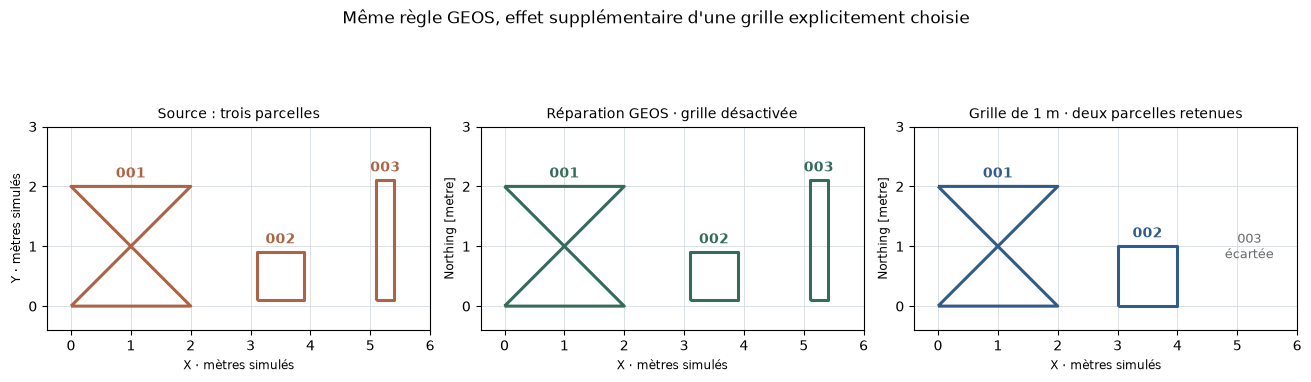

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
scenes = [(source.iloc[:3], "Source : trois parcelles", "#ac6346"),
          (repare.data, "Réparation GEOS · grille désactivée", "#356c59"),
          (grille.data, "Grille de 1 m · deux parcelles retenues", "#315b88")]
for ax, (data, title, color) in zip(axes, scenes):
    data.boundary.plot(ax=ax, color=color, linewidth=2.2)
    for _, row in data.iterrows():
        x0, y0, x1, y1 = row.geometry.bounds
        ax.text((x0 + x1) / 2, y1 + .15, row.parcelle_id, ha="center", color=color, weight="bold")
    ax.set_xlim(-.4, 6)
    ax.set_ylim(-.4, 3)
    ax.set_aspect("equal")
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.grid(color="#d5dbdf", linewidth=.6, zorder=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("X · mètres simulés")
axes[0].set_ylabel("Y · mètres simulés")
axes[2].text(5.2, .8, "003\nécartée", ha="center", color="#6b6b6b", fontsize=9)
fig.suptitle("Même règle GEOS, effet supplémentaire d'une grille explicitement choisie", fontsize=12)
plt.show()

## Exercice et passage aux données de l'étude

**Question.** Si une couche de parcelles est en longitude/latitude et que `metric_crs="EPSG:2154"` est fourni, `tolerance=0.01` signifie-t-il un centimètre ?

**Réponse.** Non. Le pas est défini dans le SCR source ; une grille positive sur une source géographique est refusée. `metric_crs` sert aux surfaces et longueurs. Il faut préparer une source projetée adaptée, vérifier ses unités, puis choisir un pas justifié par l'étude.

**Question.** Le carré valide `002` devait-il rester strictement inchangé ?

**Réponse.** Oui avec le pas nul. Avec une grille positive, ses coordonnées peuvent changer, même si la réparation GEOS n'était pas nécessaire. `repair_changed` et `precision_changed` distinguent ces étapes.

Dans la fenêtre Cartomize, le parcours **Traitements vectoriels → Diagnostic détaillé / Réparation avec rapport** expose la couche, l'identifiant, les politiques et le pas de grille avec son unité. Après calcul, consulter le rapport, les anomalies et la comparaison avant/après.

Pour reproduire la preuve réelle séparée, depuis le dépôt :

```bash
python scripts/validate_g01_real.py --data chemin/vers/cache --output resultats/validation_g01.json
```

Ce script vérifie les données historiques épinglées de RDC et de Paris, conserve leurs empreintes et distingue les scénarios de validation des recommandations métier. Les preuves historiques M08 ne sont pas remplacées. Les règles de couverture entre parcelles relèvent de G02 ; le choix d'enregistrements en double relève de G03.

**Références :** [make_valid](https://shapely.readthedocs.io/en/stable/reference/shapely.make_valid.html), [set_precision](https://shapely.readthedocs.io/en/stable/reference/shapely.set_precision.html), [guide G01 et preuves](../../docs/G01_GEOMETRY_QUALITY.md).